In [1]:
import pandas as pd

orders = pd.read_csv("../cleaned_data/orders_cleaned.csv")
customers = pd.read_csv("../cleaned_data/customers_cleaned.csv")
order_items = pd.read_csv("../cleaned_data/order_items_cleaned.csv")
products = pd.read_csv("../cleaned_data/products_cleaned.csv")
sellers = pd.read_csv("../cleaned_data/sellers_cleaned.csv")
payments = pd.read_csv("../cleaned_data/payments_cleaned.csv")
reviews = pd.read_csv("../cleaned_data/reviews_cleaned.csv")
category_translation = pd.read_csv("../cleaned_data/category_translation_cleaned.csv")
geolocation = pd.read_csv("../cleaned_data/geolocation_cleaned.csv")

In [2]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[date_cols] = orders[date_cols].apply(pd.to_datetime)

In [3]:
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"]
)

In [4]:
orders[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [5]:
order_items["shipping_limit_date"].dtype

dtype('<M8[us]')

In [6]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

delivered_orders.shape[0]

96478

In [7]:
delivered_items = order_items[
    order_items['order_id'].isin(delivered_orders['order_id'])
]

delivered_items.shape

(110197, 7)

In [8]:
product_revenue = delivered_items['price'].sum()

freight_revenue = delivered_items['freight_value'].sum()

total_item_value = product_revenue + freight_revenue

print("Product Revenue:", product_revenue)
print("Freight Revenue:", freight_revenue)
print("Total Item Value:", total_item_value)

Product Revenue: 13221498.11
Freight Revenue: 2198275.64
Total Item Value: 15419773.75


In [9]:
product_aov = product_revenue / delivered_orders.shape[0]

aov_including_freight = total_item_value / delivered_orders.shape[0]

print("Product AOV:", round(product_aov, 2))
print("AOV Including Freight:", round(aov_including_freight, 2))

Product AOV: 137.04
AOV Including Freight: 159.83


In [10]:
delivered_items_analysis = delivered_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

delivered_items_analysis.shape

(110197, 8)

In [11]:
delivered_items_analysis["order_month"] = (
    delivered_items_analysis['order_purchase_timestamp'].dt.to_period('M')
)

In [12]:
monthly_revenue = (
    delivered_items_analysis
    .groupby("order_month")["price"]
    .sum()
)

monthly_revenue

order_month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: price, dtype: float64

In [13]:
monthly_growth = monthly_revenue.pct_change() * 100

monthly_growth

order_month
2016-09             NaN
2016-10    2.977709e+04
2016-12   -9.997297e+01
2017-01    1.025573e+06
2017-02    1.095052e+02
2017-03    5.335737e+01
2017-04   -5.158471e+00
2017-05    4.364009e+01
2017-06   -1.377674e+01
2017-07    1.414502e+01
2017-08    1.517743e+01
2017-09    9.500631e+00
2017-10    6.725058e+00
2017-11    5.237469e+01
2017-12   -2.649740e+01
2018-01    2.735575e+01
2018-02   -1.062114e+01
2018-03    1.535738e+01
2018-04    2.116506e+00
2018-05    4.119630e-01
2018-06   -1.242571e+01
2018-07    1.387210e+00
2018-08   -3.384608e+00
Freq: M, Name: price, dtype: float64

In [14]:
all_months = pd.date_range(
    start=monthly_revenue.index.min().to_timestamp(),
    end=monthly_revenue.index.max().to_timestamp(),
    freq="MS"
).to_period("M")

monthly_revenue_complete = monthly_revenue.reindex(
    all_months,
    fill_value=0
)

monthly_revenue_complete

2016-09       134.97
2016-10     40325.11
2016-11         0.00
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: price, dtype: float64

In [15]:
monthly_growth_complete = (
    monthly_revenue_complete.pct_change(fill_method=None) * 100
)

monthly_growth_complete

2016-09             NaN
2016-10    2.977709e+04
2016-11   -1.000000e+02
2016-12             inf
2017-01    1.025573e+06
2017-02    1.095052e+02
2017-03    5.335737e+01
2017-04   -5.158471e+00
2017-05    4.364009e+01
2017-06   -1.377674e+01
2017-07    1.414502e+01
2017-08    1.517743e+01
2017-09    9.500631e+00
2017-10    6.725058e+00
2017-11    5.237469e+01
2017-12   -2.649740e+01
2018-01    2.735575e+01
2018-02   -1.062114e+01
2018-03    1.535738e+01
2018-04    2.116506e+00
2018-05    4.119630e-01
2018-06   -1.242571e+01
2018-07    1.387210e+00
2018-08   -3.384608e+00
Freq: M, Name: price, dtype: float64

In [16]:
previous_month_revenue = monthly_revenue_complete.shift(1)

monthly_growth_clean = (
    monthly_revenue_complete.pct_change(fill_method=None) * 100
).where(previous_month_revenue > 0)

monthly_growth_clean = monthly_growth_clean.round(2)

monthly_growth_clean

2016-09           NaN
2016-10      29777.09
2016-11       -100.00
2016-12           NaN
2017-01    1025573.03
2017-02        109.51
2017-03         53.36
2017-04         -5.16
2017-05         43.64
2017-06        -13.78
2017-07         14.15
2017-08         15.18
2017-09          9.50
2017-10          6.73
2017-11         52.37
2017-12        -26.50
2018-01         27.36
2018-02        -10.62
2018-03         15.36
2018-04          2.12
2018-05          0.41
2018-06        -12.43
2018-07          1.39
2018-08         -3.38
Freq: M, Name: price, dtype: float64

In [17]:
delivered_orders_analysis = delivered_orders.copy()

delivered_orders_analysis["order_month"] = (
    delivered_orders_analysis["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    delivered_orders_analysis.groupby("order_month")["order_id"]
    .nunique()
    .reindex(all_months, fill_value=0)
)

monthly_orders

2016-09       1
2016-10     265
2016-11       0
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3546
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4150
2017-10    4478
2017-11    7289
2017-12    5513
2018-01    7069
2018-02    6555
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6099
2018-07    6159
2018-08    6351
Freq: M, Name: order_id, dtype: int64

In [18]:
monthly_aov = (
    monthly_revenue_complete
    .div(monthly_orders)
    .round(2)
)

monthly_aov

2016-09    134.97
2016-10    152.17
2016-11       NaN
2016-12     10.90
2017-01    149.06
2017-02    141.70
2017-03    141.08
2017-04    147.92
2017-05    138.00
2017-06    134.58
2017-07    124.38
2017-08    132.29
2017-09    146.36
2017-10    144.76
2017-11    135.51
2017-12    131.69
2018-01    130.80
2018-02    126.08
2018-03    136.14
2018-04    143.21
2018-05    144.84
2018-06    140.36
2018-07    140.92
2018-08    132.04
Freq: M, dtype: float64

In [19]:
monthly_summary = pd.DataFrame({
    "revenue": monthly_revenue_complete,
    "orders": monthly_orders,
    "aov": monthly_aov
})

monthly_summary

,revenue,orders,aov
2016-09,134.97,1,134.97
2016-10,40325.11,265,152.17
2016-11,0.00,0,NaN
2016-12,10.90,1,10.90
2017-01,111798.36,750,149.06
2017-02,234223.40,1653,141.70
2017-03,359198.85,2546,141.08
2017-04,340669.68,2303,147.92
2017-05,489338.25,3546,138.00
2017-06,421923.37,3135,134.58


In [20]:
monthly_analysis = monthly_summary.copy()

monthly_analysis["revenue_growth_pct"] = (
    monthly_analysis["revenue"].pct_change(fill_method=None) * 100
)

monthly_analysis["orders_growth_pct"] = (
    monthly_analysis["orders"].pct_change(fill_method=None) * 100
)

monthly_analysis["aov_growth_pct"] = (
    monthly_analysis["aov"].pct_change(fill_method=None) * 100
)

monthly_analysis = monthly_analysis.round(2)

monthly_analysis

,revenue,orders,aov,revenue_growth_pct,orders_growth_pct,aov_growth_pct
2016-09,134.97,1,134.97,NaN,NaN,NaN
2016-10,40325.11,265,152.17,29777.09,26400.00,12.74
2016-11,0.00,0,NaN,-100.00,-100.00,NaN
2016-12,10.90,1,10.90,inf,inf,NaN
2017-01,111798.36,750,149.06,1025573.03,74900.00,1267.52
2017-02,234223.40,1653,141.70,109.51,120.40,-4.94
2017-03,359198.85,2546,141.08,53.36,54.02,-0.44
2017-04,340669.68,2303,147.92,-5.16,-9.54,4.85
2017-05,489338.25,3546,138.00,43.64,53.97,-6.71
2017-06,421923.37,3135,134.58,-13.78,-11.59,-2.48


In [21]:
delivered_items_products = delivered_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

delivered_items_products.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [22]:
category_revenue = (
    delivered_items_products
    .groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)

category_revenue.head(10)

product_category_name
beleza_saude              1233131.72
relogios_presentes        1166176.98
cama_mesa_banho           1023434.76
esporte_lazer              954852.55
informatica_acessorios     888724.61
moveis_decoracao           711927.69
utilidades_domesticas      615628.69
cool_stuff                 610204.10
automotivo                 578966.65
brinquedos                 471286.48
Name: price, dtype: float64

In [23]:
category_orders = (
    delivered_items_products
    .groupby("product_category_name")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

category_orders.head(10)

product_category_name
cama_mesa_banho           9272
beleza_saude              8647
esporte_lazer             7530
informatica_acessorios    6530
moveis_decoracao          6307
utilidades_domesticas     5743
relogios_presentes        5495
telefonia                 4093
automotivo                3810
brinquedos                3804
Name: order_id, dtype: int64

In [24]:
category_aov = (
    category_revenue
    .div(category_orders)
    .round(2)
    .sort_values(ascending=False)
)

category_aov.head(10)

product_category_name
pcs                                              1235.50
portateis_casa_forno_e_cafe                       647.08
eletrodomesticos_2                                475.57
agro_industria_e_comercio                         398.68
portateis_cozinha_e_preparadores_de_alimentos     302.59
instrumentos_musicais                             301.66
eletroportateis                                   300.09
telefonia_fixa                                    260.92
construcao_ferramentas_seguranca                  243.86
climatizacao                                      216.76
dtype: float64

In [25]:
top_aov_categories = category_aov.head(10).index

category_orders.loc[top_aov_categories]

product_category_name
pcs                                              177
portateis_casa_forno_e_cafe                       72
eletrodomesticos_2                               227
agro_industria_e_comercio                        177
portateis_cozinha_e_preparadores_de_alimentos     13
instrumentos_musicais                            611
eletroportateis                                  609
telefonia_fixa                                   212
construcao_ferramentas_seguranca                 159
climatizacao                                     246
Name: order_id, dtype: int64

In [26]:
category_summary = pd.concat(
    [
        category_revenue.rename("revenue"),
        category_orders.rename("orders"),
        category_aov.rename("avg_revenue_per_order")
    ],
    axis=1
)

category_summary.head()

,revenue,orders,avg_revenue_per_order
product_category_name,,,
beleza_saude,1233131.72,8647,142.61
relogios_presentes,1166176.98,5495,212.23
cama_mesa_banho,1023434.76,9272,110.38
esporte_lazer,954852.55,7530,126.81
informatica_acessorios,888724.61,6530,136.10


In [27]:
total_category_revenue = category_summary["revenue"].sum()

category_summary["revenue_share_pct"] = (
    category_summary["revenue"]
    .div(total_category_revenue)
    .mul(100)
    .round(2)
)

category_summary = category_summary.sort_values(
    "revenue",
    ascending=False
)

category_summary.head(10)

,revenue,orders,avg_revenue_per_order,revenue_share_pct
product_category_name,,,,
beleza_saude,1233131.72,8647,142.61,9.33
relogios_presentes,1166176.98,5495,212.23,8.82
cama_mesa_banho,1023434.76,9272,110.38,7.74
esporte_lazer,954852.55,7530,126.81,7.22
informatica_acessorios,888724.61,6530,136.10,6.72
moveis_decoracao,711927.69,6307,112.88,5.38
utilidades_domesticas,615628.69,5743,107.20,4.66
cool_stuff,610204.10,3559,171.45,4.62
automotivo,578966.65,3810,151.96,4.38


In [28]:
category_summary_english = (
    category_summary
    .reset_index()
    .merge(
        category_translation[
            ["product_category_name", "product_category_name_english"]
        ],
        on="product_category_name",
        how="left"
    )
)

category_summary_english.head(10)

,product_category_name,revenue,orders,avg_revenue_per_order,revenue_share_pct,product_category_name_english
0,beleza_saude,1233131.72,8647,142.61,9.33,health_beauty
1,relogios_presentes,1166176.98,5495,212.23,8.82,watches_gifts
2,cama_mesa_banho,1023434.76,9272,110.38,7.74,bed_bath_table
3,esporte_lazer,954852.55,7530,126.81,7.22,sports_leisure
4,informatica_acessorios,888724.61,6530,136.10,6.72,computers_accessories
5,moveis_decoracao,711927.69,6307,112.88,5.38,furniture_decor
6,utilidades_domesticas,615628.69,5743,107.20,4.66,housewares
7,cool_stuff,610204.10,3559,171.45,4.62,cool_stuff
8,automotivo,578966.65,3810,151.96,4.38,auto
9,brinquedos,471286.48,3804,123.89,3.56,toys


In [29]:
category_items = (
    delivered_items_products
    .groupby("product_category_name")
    .size()
    .sort_values(ascending=False)
    .rename("items_sold")
)

category_items.head(10)

product_category_name
cama_mesa_banho           10953
beleza_saude               9465
esporte_lazer              8431
moveis_decoracao           8160
informatica_acessorios     7644
utilidades_domesticas      6795
relogios_presentes         5859
telefonia                  4430
ferramentas_jardim         4268
automotivo                 4140
Name: items_sold, dtype: int64

In [30]:
category_avg_price = (
    category_revenue
    .div(category_items)
    .round(2)
    .sort_values(ascending=False)
)

category_avg_price.head(10)

product_category_name
pcs                                              1098.92
portateis_casa_forno_e_cafe                       638.21
eletrodomesticos_2                                467.33
agro_industria_e_comercio                         342.55
instrumentos_musicais                             283.13
portateis_cozinha_e_preparadores_de_alimentos     280.97
eletroportateis                                   277.74
telefonia_fixa                                    216.92
construcao_ferramentas_seguranca                  211.88
relogios_presentes                                199.04
dtype: float64

In [31]:
category_summary_english["items_sold"] = category_items

category_summary_english["avg_price_per_item"] = category_avg_price

category_summary_english.head(10)

,product_category_name,revenue,orders,avg_revenue_per_order,revenue_share_pct,product_category_name_english,items_sold,avg_price_per_item
0,beleza_saude,1233131.72,8647,142.61,9.33,health_beauty,NaN,NaN
1,relogios_presentes,1166176.98,5495,212.23,8.82,watches_gifts,NaN,NaN
2,cama_mesa_banho,1023434.76,9272,110.38,7.74,bed_bath_table,NaN,NaN
3,esporte_lazer,954852.55,7530,126.81,7.22,sports_leisure,NaN,NaN
4,informatica_acessorios,888724.61,6530,136.10,6.72,computers_accessories,NaN,NaN
5,moveis_decoracao,711927.69,6307,112.88,5.38,furniture_decor,NaN,NaN
6,utilidades_domesticas,615628.69,5743,107.20,4.66,housewares,NaN,NaN
7,cool_stuff,610204.10,3559,171.45,4.62,cool_stuff,NaN,NaN
8,automotivo,578966.65,3810,151.96,4.38,auto,NaN,NaN
9,brinquedos,471286.48,3804,123.89,3.56,toys,NaN,NaN


In [32]:
category_items_df = (
    category_items
    .rename("items_sold")
    .reset_index()
)

category_items_df.head()

,product_category_name,items_sold
0,cama_mesa_banho,10953
1,beleza_saude,9465
2,esporte_lazer,8431
3,moveis_decoracao,8160
4,informatica_acessorios,7644


In [33]:
category_avg_price_df = (
    category_avg_price
    .rename("avg_price_per_item")
    .reset_index()
)

category_avg_price_df.head()

,product_category_name,avg_price_per_item
0,pcs,1098.92
1,portateis_casa_forno_e_cafe,638.21
2,eletrodomesticos_2,467.33
3,agro_industria_e_comercio,342.55
4,instrumentos_musicais,283.13


In [34]:
category_summary_english = category_summary_english.merge(
    category_items_df,
    on="product_category_name",
    how="left"
)

category_summary_english = category_summary_english.merge(
    category_avg_price_df,
    on="product_category_name",
    how="left"
)

category_summary_english.head(10)

,product_category_name,revenue,orders,avg_revenue_per_order,revenue_share_pct,product_category_name_english,items_sold_x,avg_price_per_item_x,items_sold_y,avg_price_per_item_y
0,beleza_saude,1233131.72,8647,142.61,9.33,health_beauty,NaN,NaN,9465,130.28
1,relogios_presentes,1166176.98,5495,212.23,8.82,watches_gifts,NaN,NaN,5859,199.04
2,cama_mesa_banho,1023434.76,9272,110.38,7.74,bed_bath_table,NaN,NaN,10953,93.44
3,esporte_lazer,954852.55,7530,126.81,7.22,sports_leisure,NaN,NaN,8431,113.25
4,informatica_acessorios,888724.61,6530,136.10,6.72,computers_accessories,NaN,NaN,7644,116.26
5,moveis_decoracao,711927.69,6307,112.88,5.38,furniture_decor,NaN,NaN,8160,87.25
6,utilidades_domesticas,615628.69,5743,107.20,4.66,housewares,NaN,NaN,6795,90.60
7,cool_stuff,610204.10,3559,171.45,4.62,cool_stuff,NaN,NaN,3718,164.12
8,automotivo,578966.65,3810,151.96,4.38,auto,NaN,NaN,4140,139.85
9,brinquedos,471286.48,3804,123.89,3.56,toys,NaN,NaN,4030,116.94


In [35]:
category_summary_english = category_summary_english.drop(
    columns=["items_sold_x", "avg_price_per_item_x"]
)

category_summary_english.head(10)

,product_category_name,revenue,orders,avg_revenue_per_order,revenue_share_pct,product_category_name_english,items_sold_y,avg_price_per_item_y
0,beleza_saude,1233131.72,8647,142.61,9.33,health_beauty,9465,130.28
1,relogios_presentes,1166176.98,5495,212.23,8.82,watches_gifts,5859,199.04
2,cama_mesa_banho,1023434.76,9272,110.38,7.74,bed_bath_table,10953,93.44
3,esporte_lazer,954852.55,7530,126.81,7.22,sports_leisure,8431,113.25
4,informatica_acessorios,888724.61,6530,136.10,6.72,computers_accessories,7644,116.26
5,moveis_decoracao,711927.69,6307,112.88,5.38,furniture_decor,8160,87.25
6,utilidades_domesticas,615628.69,5743,107.20,4.66,housewares,6795,90.60
7,cool_stuff,610204.10,3559,171.45,4.62,cool_stuff,3718,164.12
8,automotivo,578966.65,3810,151.96,4.38,auto,4140,139.85
9,brinquedos,471286.48,3804,123.89,3.56,toys,4030,116.94


In [36]:
category_summary_english = category_summary_english.rename(
    columns={
        "items_sold_y": "items_sold",
        "avg_price_per_item_y": "avg_price_per_item"
    }
)

category_summary_english.head(10)

,product_category_name,revenue,orders,avg_revenue_per_order,revenue_share_pct,product_category_name_english,items_sold,avg_price_per_item
0,beleza_saude,1233131.72,8647,142.61,9.33,health_beauty,9465,130.28
1,relogios_presentes,1166176.98,5495,212.23,8.82,watches_gifts,5859,199.04
2,cama_mesa_banho,1023434.76,9272,110.38,7.74,bed_bath_table,10953,93.44
3,esporte_lazer,954852.55,7530,126.81,7.22,sports_leisure,8431,113.25
4,informatica_acessorios,888724.61,6530,136.10,6.72,computers_accessories,7644,116.26
5,moveis_decoracao,711927.69,6307,112.88,5.38,furniture_decor,8160,87.25
6,utilidades_domesticas,615628.69,5743,107.20,4.66,housewares,6795,90.60
7,cool_stuff,610204.10,3559,171.45,4.62,cool_stuff,3718,164.12
8,automotivo,578966.65,3810,151.96,4.38,auto,4140,139.85
9,brinquedos,471286.48,3804,123.89,3.56,toys,4030,116.94


<Axes: title={'center': 'Top 10 Product Categories by Revenue'}, xlabel='Revenue (R$)', ylabel='Product Category'>

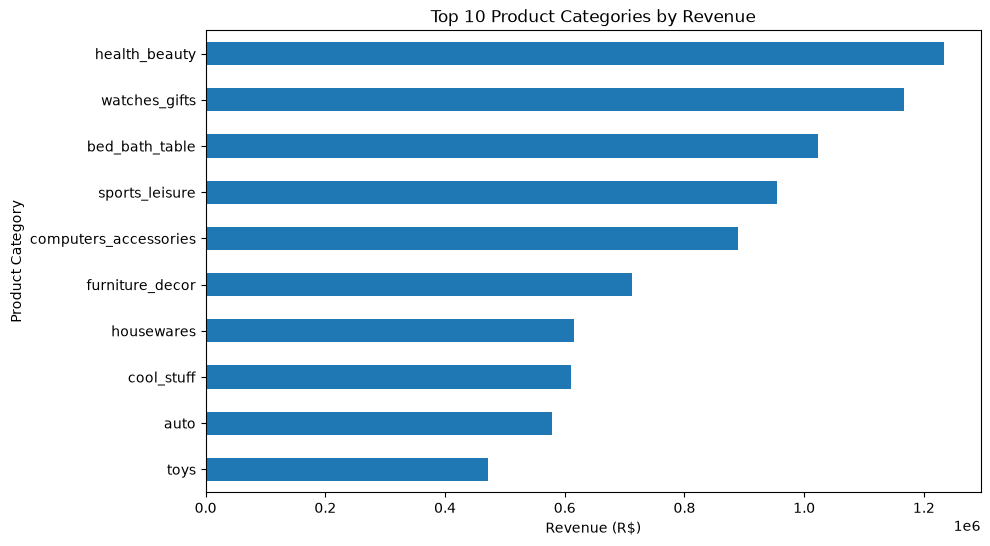

In [37]:
top_10_revenue = (
    category_summary_english
    .head(10)
    .sort_values("revenue", ascending=True)
)

top_10_revenue.plot(
    x="product_category_name_english",
    y="revenue",
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Revenue",
    xlabel="Revenue (R$)",
    ylabel="Product Category",
    legend=False
)

<Axes: title={'center': 'Top 10 Product Categories by Items Sold'}, xlabel='Number of Items Sold', ylabel='Product Category'>

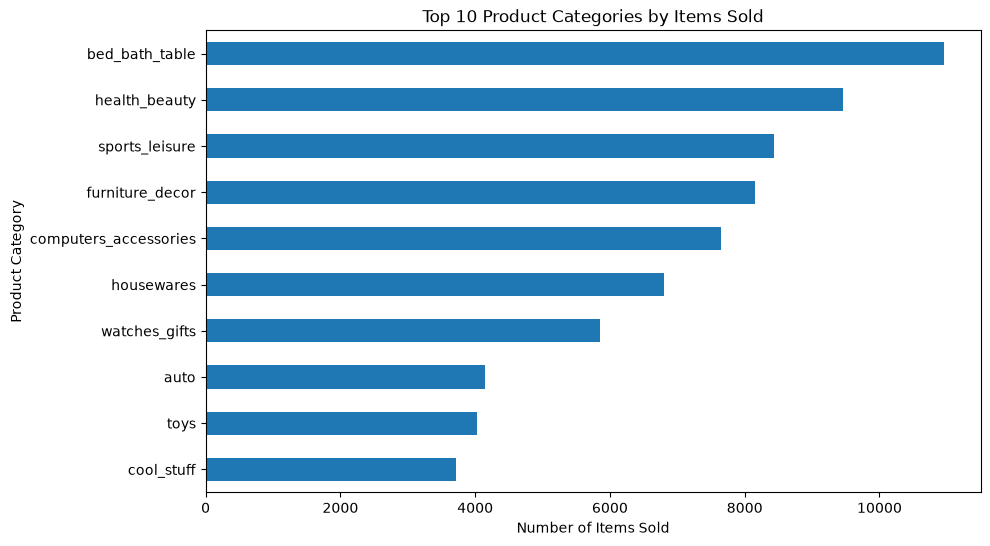

In [38]:
top_10_items = (
    category_summary_english
    .head(10)
    .sort_values("items_sold", ascending=True)
)

top_10_items.plot(
    x="product_category_name_english",
    y="items_sold",
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Items Sold",
    xlabel="Number of Items Sold",
    ylabel="Product Category",
    legend=False
)

In [39]:
orders_customers = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6


In [40]:
customer_order_count = (
    orders_customers
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .rename("order_count")
)

customer_order_count.head()

customer_unique_id
0000366f3b9a7992bf8c76cfdf3221e2    1
0000b849f77a49e4a4ce2b2a4ca5be3f    1
0000f46a3911fa3c0805444483337064    1
0000f6ccb0745a6a4b88665a16c9f078    1
0004aac84e0df4da2b147fca70cf8255    1
Name: order_count, dtype: int64

In [41]:
customer_order_distribution = (
    customer_order_count
    .value_counts()
    .sort_index()
)

customer_order_distribution

order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [42]:
one_time_customers = (customer_order_count == 1).sum()

repeat_customers = (customer_order_count > 1).sum()

total_customers = customer_order_count.shape[0]

one_time_customers, repeat_customers, total_customers

(np.int64(93099), np.int64(2997), 96096)

In [43]:
repeat_customer_rate = (
    repeat_customers / total_customers * 100
).round(2)

one_time_customer_rate = (
    one_time_customers / total_customers * 100
).round(2)

repeat_customer_rate, one_time_customer_rate

(np.float64(3.12), np.float64(96.88))

In [44]:
order_revenue = (
    delivered_items
    .groupby("order_id")["price"]
    .sum()
    .rename("order_revenue")
    .reset_index()
)

order_revenue.head()

,order_id,order_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [45]:
order_customer_revenue = orders_customers.merge(
    order_revenue,
    on="order_id",
    how="inner"
)

order_customer_revenue.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [46]:
order_customer_revenue = order_customer_revenue.merge(
    customer_order_count.reset_index()[
        ["customer_unique_id", "order_count"]
    ],
    on="customer_unique_id",
    how="left"
)

order_customer_revenue.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_revenue,order_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99,2
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90,1


In [47]:
import numpy as np

In [48]:
order_customer_revenue["customer_type"] = np.where(
    order_customer_revenue["order_count"] > 1,
    "Repeat",
    "One-time"
)

order_customer_revenue.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_revenue,order_count,customer_type
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99,2,Repeat
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70,1,One-time
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90,1,One-time
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00,1,One-time
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90,1,One-time


In [49]:
customer_type_revenue = (
    order_customer_revenue
    .groupby("customer_type")["order_revenue"]
    .sum()
    .round(2)
)

customer_type_revenue

customer_type
One-time    12461120.25
Repeat        760377.86
Name: order_revenue, dtype: float64

In [50]:
customer_type_revenue_share = (
    customer_type_revenue
    / customer_type_revenue.sum()
    * 100
).round(2)

customer_type_revenue_share

customer_type
One-time    94.25
Repeat       5.75
Name: order_revenue, dtype: float64

In [51]:
customer_type_aov = (
    order_customer_revenue
    .groupby("customer_type")["order_revenue"]
    .mean()
    .round(2)
)

customer_type_aov

customer_type
One-time    137.88
Repeat      124.67
Name: order_revenue, dtype: float64

In [52]:
customer_type_orders = (
    order_customer_revenue
    .groupby("customer_type")
    .size()
    .rename("delivered_orders")
)

customer_type_orders

customer_type
One-time    90379
Repeat       6099
Name: delivered_orders, dtype: int64

In [53]:
customer_type_count = pd.Series({
    "One-time": one_time_customers,
    "Repeat": repeat_customers
}, name="customers")

customer_type_count

One-time    93099
Repeat       2997
Name: customers, dtype: int64

In [54]:
customer_summary = pd.concat(
    [
        customer_type_count,
        customer_type_orders,
        customer_type_revenue.rename("revenue"),
        customer_type_revenue_share.rename("revenue_share_pct"),
        customer_type_aov.rename("avg_revenue_per_order")
    ],
    axis=1
)

customer_summary

,customers,delivered_orders,revenue,revenue_share_pct,avg_revenue_per_order
One-time,93099,90379,12461120.25,94.25,137.88
Repeat,2997,6099,760377.86,5.75,124.67


In [55]:
customer_summary["revenue_per_customer"] = (
    customer_summary["revenue"]
    / customer_summary["customers"]
).round(2)

customer_summary

,customers,delivered_orders,revenue,revenue_share_pct,avg_revenue_per_order,revenue_per_customer
One-time,93099,90379,12461120.25,94.25,137.88,133.85
Repeat,2997,6099,760377.86,5.75,124.67,253.71


In [56]:
customer_geography = customers[
    ["customer_unique_id", "customer_state"]
].drop_duplicates()

customer_geography.head()

,customer_unique_id,customer_state
0,861eff4711a542e4b93843c6dd7febb0,SP
1,290c77bc529b7ac935b93aa66c333dc3,SP
2,060e732b5b29e8181a18229c7b0b2b5e,SP
3,259dac757896d24d7702b9acbbff3f3c,SP
4,345ecd01c38d18a9036ed96c73b8d066,SP


In [57]:
customers_by_state = (
    customer_geography
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("customer_count")
)

customers_by_state

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
PE     1609
CE     1313
PA      949
MT      876
MA      726
MS      694
PB      519
PI      482
RN      474
AL      401
SE      342
TO      273
RO      240
AM      143
AC       77
AP       67
RR       45
Name: customer_count, dtype: int64

In [58]:
order_revenue_geography = order_customer_revenue.merge(
    customer_geography,
    on="customer_unique_id",
    how="left"
)

order_revenue_geography.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_revenue,order_count,customer_type,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99,2,Repeat,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70,1,One-time,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90,1,One-time,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00,1,One-time,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90,1,One-time,SP


In [59]:
revenue_by_state = (
    order_revenue_geography
    .groupby("customer_state")["order_revenue"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
    .rename("revenue")
)

revenue_by_state

customer_state
SP    5071093.22
RJ    1760091.68
MG    1553408.86
RS     729117.37
PR     666527.21
SC     507606.62
BA     493847.55
DF     296770.80
GO     283949.39
ES     268733.35
PE     252635.05
CE     219989.18
PA     174470.59
MT     152431.62
MA     117322.18
MS     115451.97
PB     112916.71
PI      84721.00
RN      82105.66
AL      79580.72
SE      56898.18
TO      48402.51
RO      45801.66
AM      22155.84
AC      15930.97
AP      13374.81
RR       7057.47
Name: revenue, dtype: float64

In [60]:
state_summary = pd.concat(
    [
        customers_by_state,
        revenue_by_state
    ],
    axis=1
)

state_summary

,customer_count,revenue
customer_state,,
SP,40302,5071093.22
RJ,12384,1760091.68
MG,11259,1553408.86
RS,5277,729117.37
PR,4882,666527.21
SC,3534,507606.62
BA,3277,493847.55
DF,2075,296770.80
ES,1964,268733.35


In [61]:
state_summary["revenue_per_customer"] = (
    state_summary["revenue"]
    / state_summary["customer_count"]
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer
customer_state,,,
SP,40302,5071093.22,125.83
RJ,12384,1760091.68,142.13
MG,11259,1553408.86,137.97
RS,5277,729117.37,138.17
PR,4882,666527.21,136.53
SC,3534,507606.62,143.64
BA,3277,493847.55,150.70
DF,2075,296770.80,143.02
ES,1964,268733.35,136.83


In [62]:
state_summary["revenue_share_pct"] = (
    state_summary["revenue"]
    / state_summary["revenue"].sum()
    * 100
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct
customer_state,,,,
SP,40302,5071093.22,125.83,38.32
RJ,12384,1760091.68,142.13,13.30
MG,11259,1553408.86,137.97,11.74
RS,5277,729117.37,138.17,5.51
PR,4882,666527.21,136.53,5.04
SC,3534,507606.62,143.64,3.84
BA,3277,493847.55,150.70,3.73
DF,2075,296770.80,143.02,2.24
ES,1964,268733.35,136.83,2.03


In [63]:
state_summary["customer_share_pct"] = (
    state_summary["customer_count"]
    / state_summary["customer_count"].sum()
    * 100
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct
customer_state,,,,,
SP,40302,5071093.22,125.83,38.32,41.92
RJ,12384,1760091.68,142.13,13.30,12.88
MG,11259,1553408.86,137.97,11.74,11.71
RS,5277,729117.37,138.17,5.51,5.49
PR,4882,666527.21,136.53,5.04,5.08
SC,3534,507606.62,143.64,3.84,3.68
BA,3277,493847.55,150.70,3.73,3.41
DF,2075,296770.80,143.02,2.24,2.16
ES,1964,268733.35,136.83,2.03,2.04


In [64]:
state_summary["share_difference_pp"] = (
    state_summary["revenue_share_pct"]
    - state_summary["customer_share_pct"]
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp
customer_state,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60
RJ,12384,1760091.68,142.13,13.30,12.88,0.42
MG,11259,1553408.86,137.97,11.74,11.71,0.03
RS,5277,729117.37,138.17,5.51,5.49,0.02
PR,4882,666527.21,136.53,5.04,5.08,-0.04
SC,3534,507606.62,143.64,3.84,3.68,0.16
BA,3277,493847.55,150.70,3.73,3.41,0.32
DF,2075,296770.80,143.02,2.24,2.16,0.08
ES,1964,268733.35,136.83,2.03,2.04,-0.01


In [65]:
state_summary.sort_values(
    "revenue_per_customer",
    ascending=False
)

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp
customer_state,,,,,,
PB,519,112916.71,217.57,0.85,0.54,0.31
AC,77,15930.97,206.90,0.12,0.08,0.04
AP,67,13374.81,199.62,0.10,0.07,0.03
AL,401,79580.72,198.46,0.60,0.42,0.18
RO,240,45801.66,190.84,0.35,0.25,0.10
PA,949,174470.59,183.85,1.32,0.99,0.33
TO,273,48402.51,177.30,0.37,0.28,0.09
PI,482,84721.00,175.77,0.64,0.50,0.14
MT,876,152431.62,174.01,1.15,0.91,0.24


In [66]:
state_summary[
    state_summary["customer_count"] >= 1000
].sort_values(
    "revenue_per_customer",
    ascending=False
)

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp
customer_state,,,,,,
CE,1313,219989.18,167.55,1.66,1.37,0.29
PE,1609,252635.05,157.01,1.91,1.67,0.24
BA,3277,493847.55,150.70,3.73,3.41,0.32
GO,1952,283949.39,145.47,2.15,2.03,0.12
SC,3534,507606.62,143.64,3.84,3.68,0.16
DF,2075,296770.80,143.02,2.24,2.16,0.08
RJ,12384,1760091.68,142.13,13.30,12.88,0.42
RS,5277,729117.37,138.17,5.51,5.49,0.02
MG,11259,1553408.86,137.97,11.74,11.71,0.03


In [67]:
orders_by_state = (
    order_revenue_geography
    .groupby("customer_state")["order_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("order_count")
)

orders_by_state

customer_state
SP    40519
RJ    12357
MG    11364
RS     5347
PR     4927
SC     3554
BA     3258
DF     2084
ES     1996
GO     1962
PE     1600
CE     1281
PA      946
MT      888
MA      720
MS      702
PB      519
PI      476
RN      474
AL      398
SE      338
TO      274
RO      244
AM      145
AC       80
AP       67
RR       41
Name: order_count, dtype: int64

In [68]:
state_summary = state_summary.join(orders_by_state)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp,order_count
customer_state,,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60,40519
RJ,12384,1760091.68,142.13,13.30,12.88,0.42,12357
MG,11259,1553408.86,137.97,11.74,11.71,0.03,11364
RS,5277,729117.37,138.17,5.51,5.49,0.02,5347
PR,4882,666527.21,136.53,5.04,5.08,-0.04,4927
SC,3534,507606.62,143.64,3.84,3.68,0.16,3554
BA,3277,493847.55,150.70,3.73,3.41,0.32,3258
DF,2075,296770.80,143.02,2.24,2.16,0.08,2084
ES,1964,268733.35,136.83,2.03,2.04,-0.01,1996


In [69]:
state_summary["orders_per_customer"] = (
    state_summary["order_count"]
    / state_summary["customer_count"]
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp,order_count,orders_per_customer
customer_state,,,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60,40519,1.01
RJ,12384,1760091.68,142.13,13.30,12.88,0.42,12357,1.00
MG,11259,1553408.86,137.97,11.74,11.71,0.03,11364,1.01
RS,5277,729117.37,138.17,5.51,5.49,0.02,5347,1.01
PR,4882,666527.21,136.53,5.04,5.08,-0.04,4927,1.01
SC,3534,507606.62,143.64,3.84,3.68,0.16,3554,1.01
BA,3277,493847.55,150.70,3.73,3.41,0.32,3258,0.99
DF,2075,296770.80,143.02,2.24,2.16,0.08,2084,1.00
ES,1964,268733.35,136.83,2.03,2.04,-0.01,1996,1.02


In [70]:
delivered_customers_by_state = (
    order_revenue_geography
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .rename("delivered_customer_count")
)

delivered_customers_by_state

customer_state
AC       76
AL      388
AM      140
AP       66
BA     3158
CE     1258
DF     2019
ES     1928
GO     1895
MA      700
MG    11002
MS      681
MT      856
PA      922
PB      504
PE     1551
PI      464
PR     4769
RJ    11917
RN      464
RO      231
RR       40
RS     5168
SC     3449
SE      329
SP    39156
TO      267
Name: delivered_customer_count, dtype: int64

In [71]:
state_summary = state_summary.join(delivered_customers_by_state)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp,order_count,orders_per_customer,delivered_customer_count
customer_state,,,,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60,40519,1.01,39156
RJ,12384,1760091.68,142.13,13.30,12.88,0.42,12357,1.00,11917
MG,11259,1553408.86,137.97,11.74,11.71,0.03,11364,1.01,11002
RS,5277,729117.37,138.17,5.51,5.49,0.02,5347,1.01,5168
PR,4882,666527.21,136.53,5.04,5.08,-0.04,4927,1.01,4769
SC,3534,507606.62,143.64,3.84,3.68,0.16,3554,1.01,3449
BA,3277,493847.55,150.70,3.73,3.41,0.32,3258,0.99,3158
DF,2075,296770.80,143.02,2.24,2.16,0.08,2084,1.00,2019
ES,1964,268733.35,136.83,2.03,2.04,-0.01,1996,1.02,1928


In [72]:
state_summary["delivered_orders_per_customer"] = (
    state_summary["order_count"]
    / state_summary["delivered_customer_count"]
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp,order_count,orders_per_customer,delivered_customer_count,delivered_orders_per_customer
customer_state,,,,,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60,40519,1.01,39156,1.03
RJ,12384,1760091.68,142.13,13.30,12.88,0.42,12357,1.00,11917,1.04
MG,11259,1553408.86,137.97,11.74,11.71,0.03,11364,1.01,11002,1.03
RS,5277,729117.37,138.17,5.51,5.49,0.02,5347,1.01,5168,1.03
PR,4882,666527.21,136.53,5.04,5.08,-0.04,4927,1.01,4769,1.03
SC,3534,507606.62,143.64,3.84,3.68,0.16,3554,1.01,3449,1.03
BA,3277,493847.55,150.70,3.73,3.41,0.32,3258,0.99,3158,1.03
DF,2075,296770.80,143.02,2.24,2.16,0.08,2084,1.00,2019,1.03
ES,1964,268733.35,136.83,2.03,2.04,-0.01,1996,1.02,1928,1.04


In [73]:
state_summary["delivered_customer_rate_pct"] = (
    state_summary["delivered_customer_count"]
    / state_summary["customer_count"]
    * 100
).round(2)

state_summary

,customer_count,revenue,revenue_per_customer,revenue_share_pct,customer_share_pct,share_difference_pp,order_count,orders_per_customer,delivered_customer_count,delivered_orders_per_customer,delivered_customer_rate_pct
customer_state,,,,,,,,,,,
SP,40302,5071093.22,125.83,38.32,41.92,-3.60,40519,1.01,39156,1.03,97.16
RJ,12384,1760091.68,142.13,13.30,12.88,0.42,12357,1.00,11917,1.04,96.23
MG,11259,1553408.86,137.97,11.74,11.71,0.03,11364,1.01,11002,1.03,97.72
RS,5277,729117.37,138.17,5.51,5.49,0.02,5347,1.01,5168,1.03,97.93
PR,4882,666527.21,136.53,5.04,5.08,-0.04,4927,1.01,4769,1.03,97.69
SC,3534,507606.62,143.64,3.84,3.68,0.16,3554,1.01,3449,1.03,97.59
BA,3277,493847.55,150.70,3.73,3.41,0.32,3258,0.99,3158,1.03,96.37
DF,2075,296770.80,143.02,2.24,2.16,0.08,2084,1.00,2019,1.03,97.30
ES,1964,268733.35,136.83,2.03,2.04,-0.01,1996,1.02,1928,1.04,98.17


In [74]:
top_10_customer_states = (
    state_summary["customer_count"]
    .sort_values(ascending=False)
    .head(10)
)

top_10_customer_states

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_count, dtype: int64

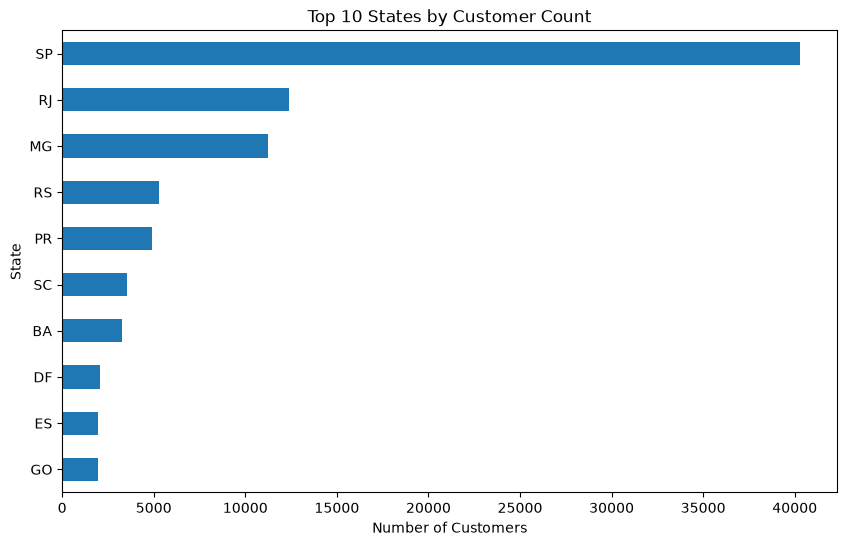

In [75]:
import matplotlib.pyplot as plt

top_10_customer_states.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 States by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.show()

In [76]:
top_10_revenue_states = (
    state_summary["revenue"]
    .sort_values(ascending=False)
    .head(10)
)

top_10_revenue_states

customer_state
SP    5071093.22
RJ    1760091.68
MG    1553408.86
RS     729117.37
PR     666527.21
SC     507606.62
BA     493847.55
DF     296770.80
GO     283949.39
ES     268733.35
Name: revenue, dtype: float64

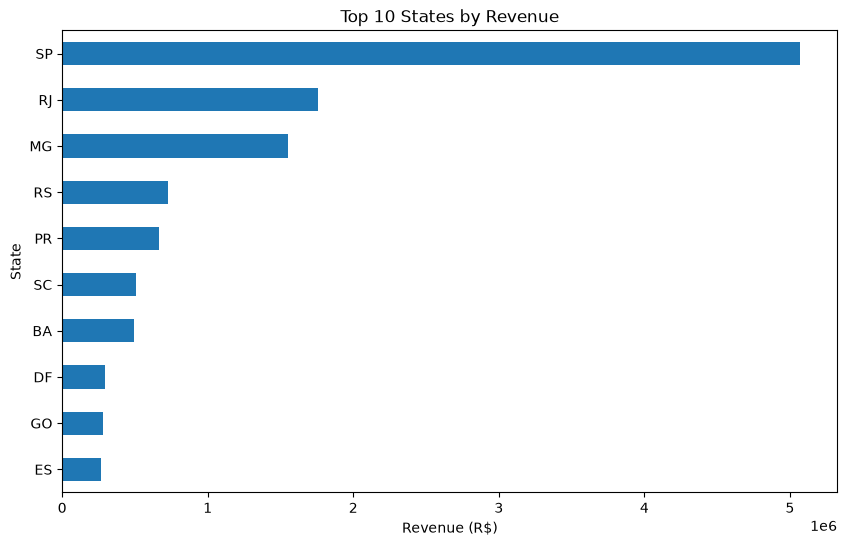

In [77]:
top_10_revenue_states.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.show()

In [78]:
top_10_state_comparison = state_summary.loc[
    top_10_customer_states.index,
    ["customer_count", "customer_share_pct", "revenue_share_pct", "share_difference_pp"]
]

top_10_state_comparison

,customer_count,customer_share_pct,revenue_share_pct,share_difference_pp
customer_state,,,,
SP,40302,41.92,38.32,-3.60
RJ,12384,12.88,13.30,0.42
MG,11259,11.71,11.74,0.03
RS,5277,5.49,5.51,0.02
PR,4882,5.08,5.04,-0.04
SC,3534,3.68,3.84,0.16
BA,3277,3.41,3.73,0.32
DF,2075,2.16,2.24,0.08
ES,1964,2.04,2.03,-0.01


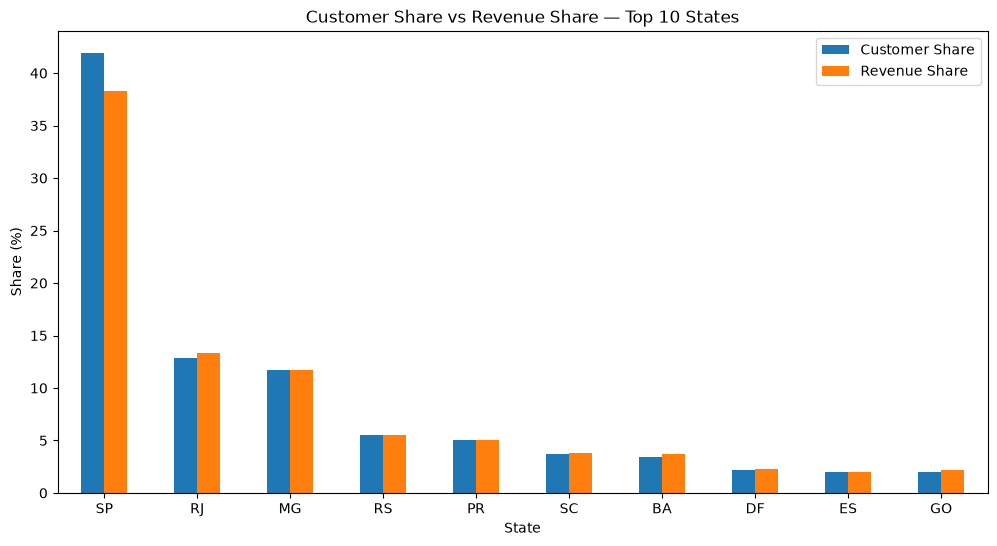

In [79]:
top_10_share_comparison = top_10_state_comparison[
    ["customer_share_pct", "revenue_share_pct"]
]

top_10_share_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Customer Share vs Revenue Share — Top 10 States")
plt.xlabel("State")
plt.ylabel("Share (%)")
plt.xticks(rotation=0)
plt.legend(["Customer Share", "Revenue Share"])
plt.show()

In [80]:
revenue_per_customer_large_states = (
    state_summary[
        state_summary["customer_count"] >= 1000
    ]["revenue_per_customer"]
    .sort_values(ascending=False)
)

revenue_per_customer_large_states

customer_state
CE    167.55
PE    157.01
BA    150.70
GO    145.47
SC    143.64
DF    143.02
RJ    142.13
RS    138.17
MG    137.97
ES    136.83
PR    136.53
SP    125.83
Name: revenue_per_customer, dtype: float64

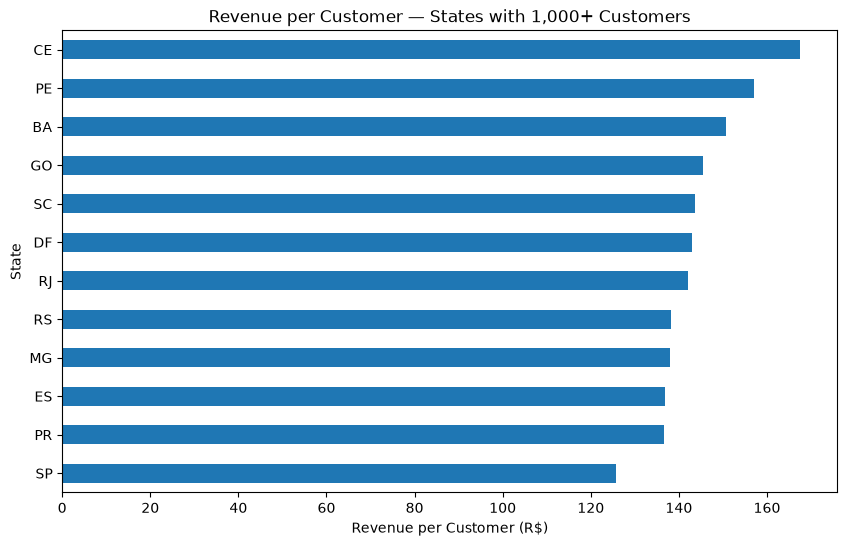

In [81]:
revenue_per_customer_large_states.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Revenue per Customer — States with 1,000+ Customers")
plt.xlabel("Revenue per Customer (R$)")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.show()

In [82]:
payment_type_share = (
    payments["payment_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

payment_type_share

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

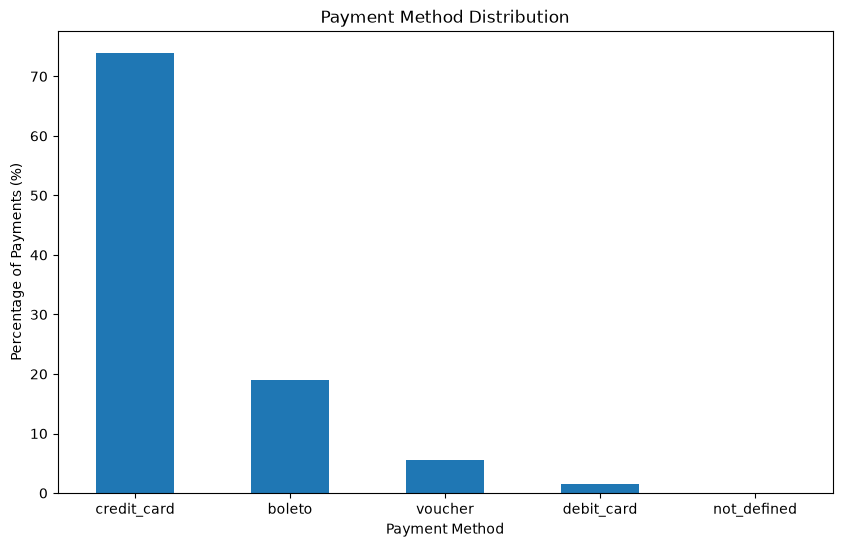

In [83]:
payment_type_share.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Payments (%)")
plt.xticks(rotation=0)
plt.show()

In [84]:
payment_value_by_type = (
    payments
    .groupby("payment_type")["payment_value"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)

payment_value_by_type

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64

In [85]:
payment_value_share = (
    payment_value_by_type
    / payment_value_by_type.sum()
    * 100
).round(2)

payment_value_share

payment_type
credit_card    78.34
boleto         17.92
voucher         2.37
debit_card      1.36
not_defined     0.00
Name: payment_value, dtype: float64

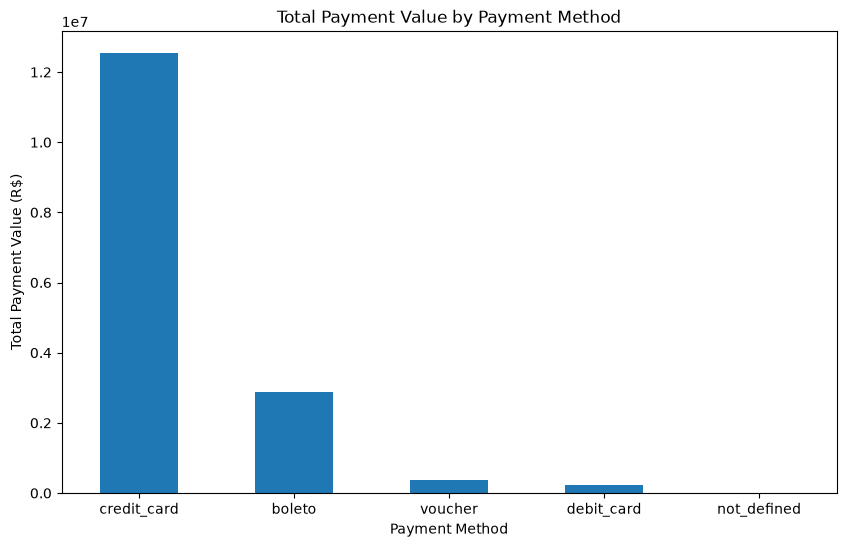

In [86]:
payment_value_by_type.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (R$)")
plt.xticks(rotation=0)
plt.show()

In [87]:
installment_counts = (
    payments["payment_installments"]
    .value_counts()
    .sort_index()
)

installment_counts

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [88]:
payments.loc[
    payments["payment_installments"] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [89]:
installment_counts_clean = (
    payments.loc[
        payments["payment_installments"] > 0,
        "payment_installments"
    ]
    .value_counts()
    .sort_index()
)

installment_counts_clean

payment_installments
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

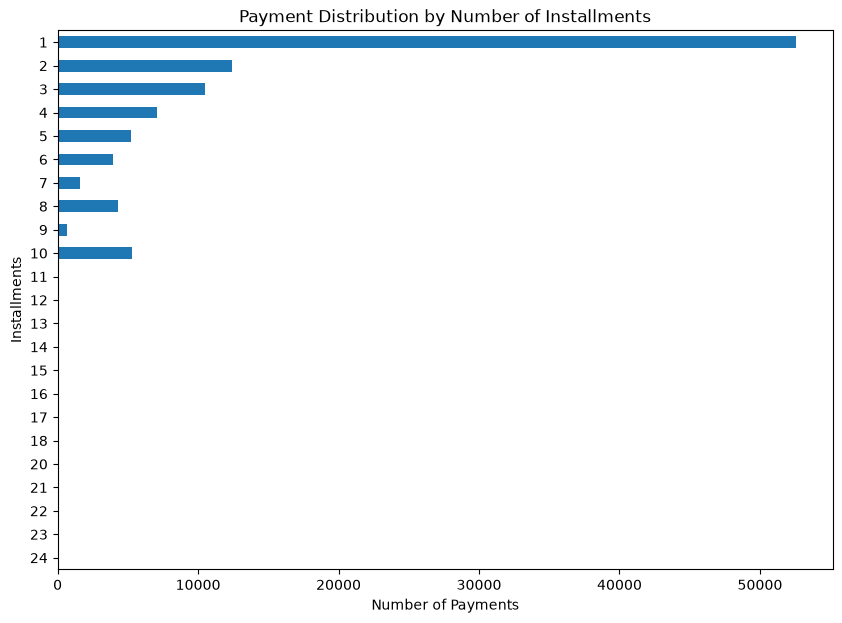

In [90]:
installment_counts_clean.plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Payment Distribution by Number of Installments")
plt.xlabel("Number of Payments")
plt.ylabel("Installments")
plt.gca().invert_yaxis()
plt.show()

In [91]:
single_installment_count = (
    (payments["payment_installments"] == 1)
    .sum()
)

multiple_installment_count = (
    (payments["payment_installments"] > 1)
    .sum()

)

single_installment_count, multiple_installment_count

(np.int64(52546), np.int64(51338))

In [92]:
total_valid_installment_payments = (
    single_installment_count
    + multiple_installment_count
)

single_installment_pct = (
    single_installment_count
    / total_valid_installment_payments
    * 100
)

multiple_installment_pct = (
    multiple_installment_count
    / total_valid_installment_payments
    * 100
)

round(single_installment_pct, 2), round(multiple_installment_pct, 2)

(np.float64(50.58), np.float64(49.42))

In [93]:
payment_installment_summary = (
    payments.assign(
        installment_group=payments["payment_installments"].apply(
            lambda x: "1 installment"
            if x == 1
            else "More than 1 installment"
            if x > 1
            else "Other"
        )
    )
    .groupby("installment_group")["payment_value"]
    .agg(["count", "mean", "sum"])
    .round(2)
)

payment_installment_summary

,count,mean,sum
installment_group,,,
1 installment,52546,112.42,5907233.36
More than 1 installment,51338,196.76,10101450.13
Other,2,94.32,188.63


In [94]:
review_score_counts = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

review_score_counts

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [95]:
review_score_pct = (
    review_score_counts
    / review_score_counts.sum()
    * 100
).round(2)

review_score_pct

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: count, dtype: float64

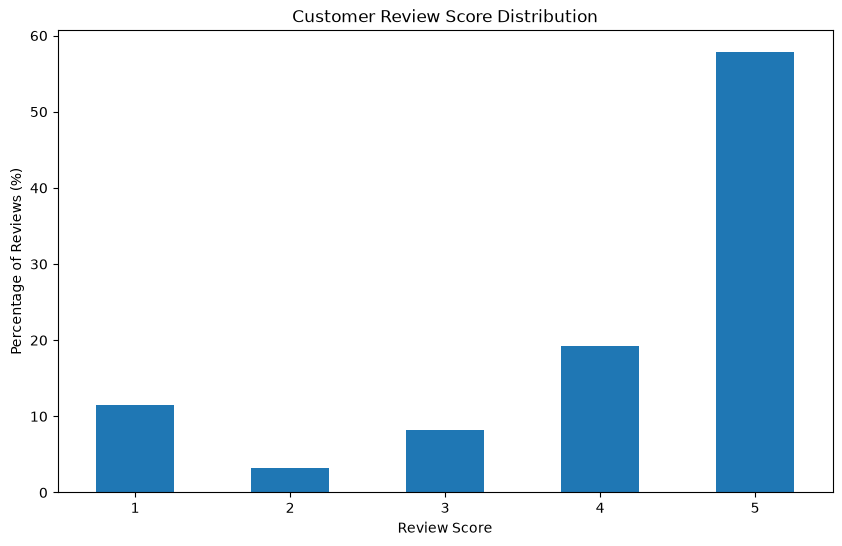

In [96]:
review_score_pct.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)

plt.show()

In [97]:
average_review_score = reviews["review_score"].mean()

round(average_review_score, 2)

np.float64(4.09)

In [98]:
low_rating_count = (
    reviews["review_score"] <= 2
).sum()

low_rating_count

np.int64(14575)

In [99]:
low_rating_pct = (
    low_rating_count
    / len(reviews)
    * 100
)

round(low_rating_pct, 2)

np.float64(14.69)

In [100]:
reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')

In [101]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [102]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
].dtypes

order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
dtype: object

In [103]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days

orders["delivery_days"].head()

0     8.0
1    13.0
2     9.0
3    13.0
4     2.0
Name: delivery_days, dtype: float64

In [104]:
reviews_with_delivery = reviews.merge(
    orders[["order_id", "delivery_days"]],
    on="order_id",
    how="left"
)

reviews_with_delivery.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,delivery_days
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,6.0
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,9.0
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,13.0
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,10.0
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,18.0


In [105]:
delivery_by_review_score = (
    reviews_with_delivery
    .groupby("review_score")["delivery_days"]
    .mean()
    .round(2)
)

delivery_by_review_score

review_score
1    20.85
2    16.19
3    13.80
4    11.85
5    10.22
Name: delivery_days, dtype: float64

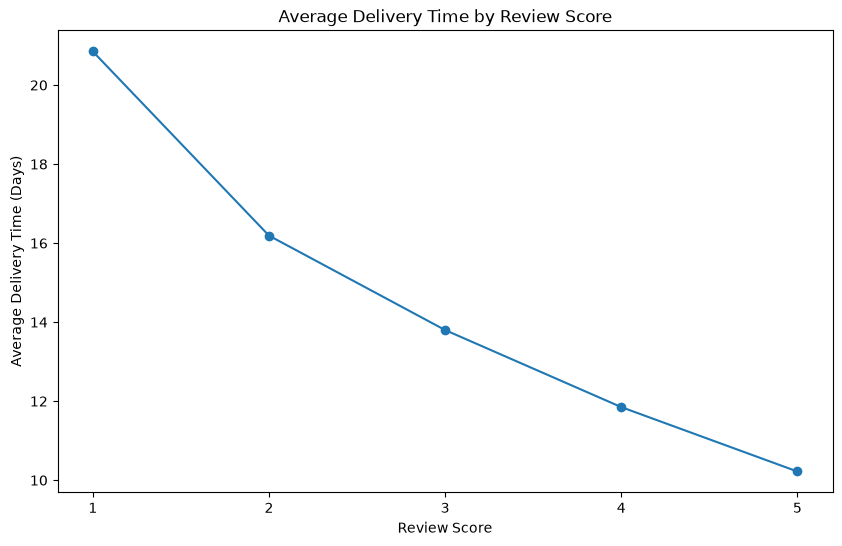

In [106]:
delivery_by_review_score.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Average Delivery Time by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Average Delivery Time (Days)")
plt.xticks([1, 2, 3, 4, 5])

plt.show()

In [107]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

orders[
    [
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days"
    ]
].head()

,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,2017-10-10 21:25:13,2017-10-18,-8.0
1,2018-08-07 15:27:45,2018-08-13,-6.0
2,2018-08-17 18:06:29,2018-09-04,-18.0
3,2017-12-02 00:28:42,2017-12-15,-13.0
4,2018-02-16 18:17:02,2018-02-26,-10.0


In [108]:
delivery_status_counts = (
    orders["delivery_delay_days"]
    .apply(
        lambda x: "Late"
        if x > 0
        else "Early/On-time"
    )
    .value_counts()
)

delivery_status_counts

delivery_delay_days
Early/On-time    92906
Late              6535
Name: count, dtype: int64

In [109]:
reviews_with_delivery = reviews_with_delivery.merge(
    orders[["order_id", "delivery_delay_days"]],
    on="order_id",
    how="left"
)

reviews_with_delivery.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,delivery_days,delivery_delay_days
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,6.0,-16.0
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,9.0,-5.0
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,13.0,-21.0
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,10.0,-20.0
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,18.0,-9.0


In [110]:
reviews_with_delivery["delivery_status"] = (
    reviews_with_delivery["delivery_delay_days"]
    .apply(
        lambda x: "Late"
        if x > 0
        else "Early/On-time"
    )
)

reviews_with_delivery[
    ["review_score", "delivery_delay_days", "delivery_status"]
].head()

,review_score,delivery_delay_days,delivery_status
0,4,-16.0,Early/On-time
1,5,-5.0,Early/On-time
2,5,-21.0,Early/On-time
3,5,-20.0,Early/On-time
4,5,-9.0,Early/On-time


In [111]:
review_by_delivery_status = (
    reviews_with_delivery
    .groupby("delivery_status")["review_score"]
    .mean()
    .round(2)
)

review_by_delivery_status

delivery_status
Early/On-time    4.21
Late             2.27
Name: review_score, dtype: float64

In [112]:
reviews_with_delivery["delivery_status"].value_counts()

delivery_status
Early/On-time    92814
Late              6410
Name: count, dtype: int64

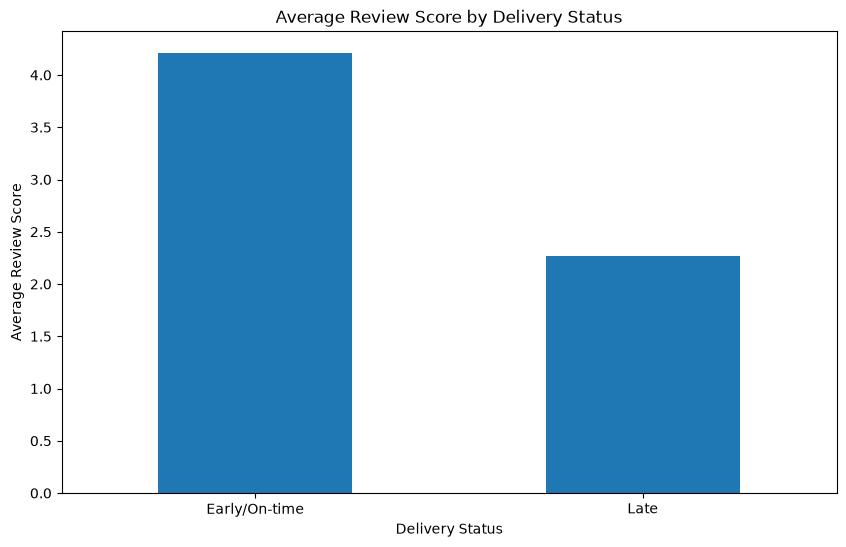

In [113]:
review_by_delivery_status.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)

plt.show()

In [114]:
reviews_with_delivery["delivery_delay_days"].isna().sum()

np.int64(2865)

In [115]:
reviews_with_delivery["delivery_status"] = (
    reviews_with_delivery["delivery_delay_days"]
    .apply(
        lambda x: "Late"
        if x > 0
        else "Early/On-time"
        if x <= 0
        else "Unknown"
    )
)

In [116]:
reviews_with_delivery["delivery_status"].value_counts()

delivery_status
Early/On-time    89949
Late              6410
Unknown           2865
Name: count, dtype: int64

In [117]:
review_by_delivery_status = (
    reviews_with_delivery[
        reviews_with_delivery["delivery_status"] != "Unknown"
    ]
    .groupby("delivery_status")["review_score"]
    .mean()
    .round(2)
)

review_by_delivery_status

delivery_status
Early/On-time    4.29
Late             2.27
Name: review_score, dtype: float64

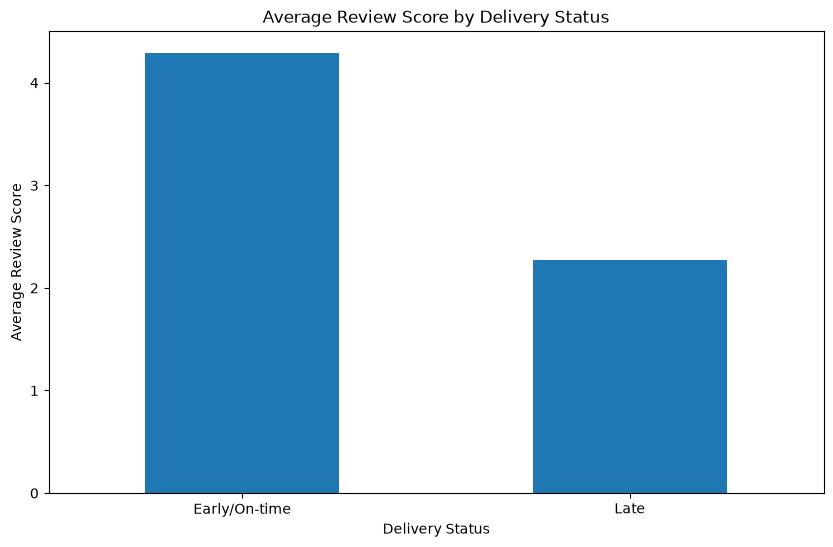

In [118]:
review_by_delivery_status.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)

plt.show()

In [119]:
review_score_difference = (
    review_by_delivery_status["Early/On-time"]
    - review_by_delivery_status["Late"]
)

round(review_score_difference, 2)

np.float64(2.02)

In [120]:
known_delivery_reviews = (
    reviews_with_delivery[
        reviews_with_delivery["delivery_status"] != "Unknown"
    ]
)

late_delivery_pct = (
    (
        known_delivery_reviews["delivery_status"] == "Late"
    ).sum()
    / len(known_delivery_reviews)
    * 100
)

round(late_delivery_pct, 2)

np.float64(6.65)

In [121]:
review_by_delivery_status_count = (
    known_delivery_reviews
    .groupby("delivery_status")["review_score"]
    .count()
)

review_by_delivery_status_count

delivery_status
Early/On-time    89949
Late              6410
Name: review_score, dtype: int64

In [122]:
review_distribution_by_delivery = (
    known_delivery_reviews
    .groupby(["delivery_status", "review_score"])
    .size()
    .unstack(fill_value=0)
)

review_distribution_by_delivery

review_score,1,2,3,4,5
delivery_status,,,,,
Early/On-time,5965,2385,7264,18335,56000
Late,3444,556,698,652,1060


In [123]:
review_distribution_pct = (
    review_distribution_by_delivery
    .div(
        review_distribution_by_delivery.sum(axis=1),
        axis=0
    )
    * 100
).round(2)

review_distribution_pct

review_score,1,2,3,4,5
delivery_status,,,,,
Early/On-time,6.63,2.65,8.08,20.38,62.26
Late,53.73,8.67,10.89,10.17,16.54


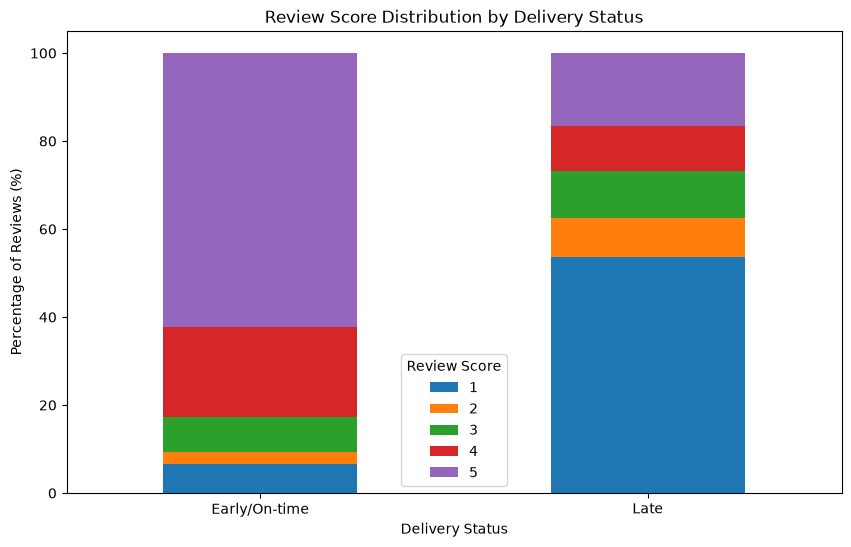

In [124]:
review_distribution_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Review Score Distribution by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.legend(title="Review Score")

plt.show()

In [125]:
reviews["review_comment_message"].notna().sum()

np.int64(40977)

In [126]:
reviews["review_comment_message"].fillna("").str.strip().eq("").sum()

np.int64(58274)

In [127]:
written_comment_pct = (
    reviews["review_comment_message"].fillna("").str.strip().ne("").mean()
    * 100
)

round(written_comment_pct, 2)

np.float64(41.27)

In [128]:
comment_rate_by_score = (
    reviews.assign(
        has_comment=(
            reviews["review_comment_message"]
            .fillna("")
            .str.strip()
            .ne("")
        )
    )
    .groupby("review_score")["has_comment"]
    .mean()
    .mul(100)
    .round(2)
)

comment_rate_by_score

review_score
1    76.54
2    68.07
3    43.48
4    31.19
5    35.82
Name: has_comment, dtype: float64

In [129]:
review_comments = (
    reviews["review_comment_message"]
    .dropna()
    .str.strip()
)

review_comments.head()

3                 Recebi bem antes do prazo estipulado.
4     Parabéns lojas lannister adorei comprar pela I...
9     aparelho eficiente. no site a marca do aparelh...
12          Mas um pouco ,travando...pelo valor ta Boa.
15    Vendedor confiável, produto ok e entrega antes...
Name: review_comment_message, dtype: str

In [130]:
review_comments_clean = (
    review_comments
    .str.lower()
)

review_comments_clean.head()

3                 recebi bem antes do prazo estipulado.
4     parabéns lojas lannister adorei comprar pela i...
9     aparelho eficiente. no site a marca do aparelh...
12          mas um pouco ,travando...pelo valor ta boa.
15    vendedor confiável, produto ok e entrega antes...
Name: review_comment_message, dtype: str

In [131]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [132]:
seller_revenue = (
    order_items
    .groupby("seller_id")["price"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)

seller_revenue.head(10)

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
Name: price, dtype: float64

In [133]:
seller_order_count = (
    order_items
    .groupby("seller_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

seller_order_count.head(10)

seller_id
6560211a19b47992c3666cc44a7e94c0    1854
4a3ca9315b744ce9f8e9374361493884    1806
cc419e0650a3c5ba77189a1882b7556a    1706
1f50f920176fa81dab994f9023523100    1404
da8622b14eb17ae2831f4ac5b9dab84a    1314
955fee9216a65b617aa5c0531780ce60    1287
7a67c85e85bb2ce8582c35f2203ad736    1160
ea8482cd71df3c1969d7b9473ff13abc    1146
4869f7a5dfa277a7dca6462dcf3b52b2    1132
3d871de0142ce09b7081e2b9d1733cb1    1080
Name: order_id, dtype: int64

In [134]:
seller_order_revenue = (
    order_items
    .groupby(["seller_id", "order_id"])["price"]
    .sum()
)

seller_avg_order_value = (
    seller_order_revenue
    .groupby("seller_id")
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

seller_avg_order_value.head(10)

seller_id
80ceebb4ee9b31afb6c6a916a574a1e2    6729.00
ee27a8f15b1dded4d213a468ba4eb391    6499.00
b37c4c02bda3161a7546a4e6d222d5b2    6018.75
585175ec331ea177fa47199e39a6170a    3549.00
abe021b01ba992245271b9aa422032df    3360.00
a00824eb9093d40e589b940ec45c4eb0    3133.32
e2a1ac9bf33e5549a2a4f834e70df2f8    2999.89
e908c0f3646e8b60375734a350d95d71    2951.00
d63c73efd41eb002280e7ec831424edb    2799.00
1444c08e64d55fb3c25f0f09c07ffcf2    2749.00
Name: price, dtype: float64

In [135]:
seller_avg_order_value.head(10).to_frame(
    name="avg_revenue_per_order"
).join(
    seller_order_count.rename("order_count")
)

,avg_revenue_per_order,order_count
seller_id,,
80ceebb4ee9b31afb6c6a916a574a1e2,6729.00,1
ee27a8f15b1dded4d213a468ba4eb391,6499.00,1
b37c4c02bda3161a7546a4e6d222d5b2,6018.75,4
585175ec331ea177fa47199e39a6170a,3549.00,1
abe021b01ba992245271b9aa422032df,3360.00,2
a00824eb9093d40e589b940ec45c4eb0,3133.32,3
e2a1ac9bf33e5549a2a4f834e70df2f8,2999.89,5
e908c0f3646e8b60375734a350d95d71,2951.00,1
d63c73efd41eb002280e7ec831424edb,2799.00,2


In [136]:
seller_avg_order_value_filtered = (
    seller_avg_order_value[
        seller_order_count >= 100
    ]
    .sort_values(ascending=False)
)

seller_avg_order_value_filtered.head(10)

seller_id
53243585a1d6dc2643021fd1853d8905    622.28
7e93a43ef30c4f03f38b393420bc753a    525.09
edb1ef5e36e0c8cd84eb3c9b003e486d    477.62
f5a590cf36251cf1162ea35bef76fe84    454.72
ccc4bbb5f32a6ab2b7066a4130f114e3    395.75
25c5c91f63607446a97b143d2d535d31    346.07
5dceca129747e92ff8ef7a997dc4f8ca    345.09
fa1c13f2614d7b5c4749cbc52fecda94    331.70
522620dcb18a6b31cd7bdf73665113a9    328.55
17a053fcb14bd219540cbde0df490be0    325.63
Name: price, dtype: float64

In [137]:
seller_performance = (
    seller_avg_order_value_filtered
    .to_frame(name="avg_revenue_per_order")
    .join(seller_order_count.rename("order_count"))
)

seller_performance.head(10)

,avg_revenue_per_order,order_count
seller_id,,
53243585a1d6dc2643021fd1853d8905,622.28,358
7e93a43ef30c4f03f38b393420bc753a,525.09,336
edb1ef5e36e0c8cd84eb3c9b003e486d,477.62,166
f5a590cf36251cf1162ea35bef76fe84,454.72,117
ccc4bbb5f32a6ab2b7066a4130f114e3,395.75,187
25c5c91f63607446a97b143d2d535d31,346.07,158
5dceca129747e92ff8ef7a997dc4f8ca,345.09,325
fa1c13f2614d7b5c4749cbc52fecda94,331.70,585
522620dcb18a6b31cd7bdf73665113a9,328.55,174


In [138]:
order_items[
    ["seller_id", "order_id", "shipping_limit_date"]
].head()

,seller_id,order_id,shipping_limit_date
0,48436dade18ac8b2bce089ec2a041202,00010242fe8c5a6d1ba2dd792cb16214,2017-09-19 09:45:35
1,dd7ddc04e1b6c2c614352b383efe2d36,00018f77f2f0320c557190d7a144bdd3,2017-05-03 11:05:13
2,5b51032eddd242adc84c38acab88f23d,000229ec398224ef6ca0657da4fc703e,2018-01-18 14:48:30
3,9d7a1d34a5052409006425275ba1c2b4,00024acbcdf0a6daa1e931b038114c75,2018-08-15 10:10:18
4,df560393f3a51e74553ab94004ba5c87,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-13 13:57:51


In [139]:
seller_shipping = order_items[
    ["seller_id", "order_id", "shipping_limit_date"]
].merge(
    orders[
        ["order_id", "order_delivered_carrier_date"]
    ],
    on="order_id",
    how="left"
)

seller_shipping.head()

,seller_id,order_id,shipping_limit_date,order_delivered_carrier_date
0,48436dade18ac8b2bce089ec2a041202,00010242fe8c5a6d1ba2dd792cb16214,2017-09-19 09:45:35,2017-09-19 18:34:16
1,dd7ddc04e1b6c2c614352b383efe2d36,00018f77f2f0320c557190d7a144bdd3,2017-05-03 11:05:13,2017-05-04 14:35:00
2,5b51032eddd242adc84c38acab88f23d,000229ec398224ef6ca0657da4fc703e,2018-01-18 14:48:30,2018-01-16 12:36:48
3,9d7a1d34a5052409006425275ba1c2b4,00024acbcdf0a6daa1e931b038114c75,2018-08-15 10:10:18,2018-08-10 13:28:00
4,df560393f3a51e74553ab94004ba5c87,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-13 13:57:51,2017-02-16 09:46:09


In [140]:
seller_shipping["shipping_status"] = (
    seller_shipping["order_delivered_carrier_date"]
    <= seller_shipping["shipping_limit_date"]
).map({
    True: "On time",
    False: "Late"
})

seller_shipping.head()

,seller_id,order_id,shipping_limit_date,order_delivered_carrier_date,shipping_status
0,48436dade18ac8b2bce089ec2a041202,00010242fe8c5a6d1ba2dd792cb16214,2017-09-19 09:45:35,2017-09-19 18:34:16,Late
1,dd7ddc04e1b6c2c614352b383efe2d36,00018f77f2f0320c557190d7a144bdd3,2017-05-03 11:05:13,2017-05-04 14:35:00,Late
2,5b51032eddd242adc84c38acab88f23d,000229ec398224ef6ca0657da4fc703e,2018-01-18 14:48:30,2018-01-16 12:36:48,On time
3,9d7a1d34a5052409006425275ba1c2b4,00024acbcdf0a6daa1e931b038114c75,2018-08-15 10:10:18,2018-08-10 13:28:00,On time
4,df560393f3a51e74553ab94004ba5c87,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-13 13:57:51,2017-02-16 09:46:09,Late


In [141]:
seller_shipping["order_delivered_carrier_date"].isna().sum()

np.int64(1194)

In [142]:
seller_shipping.loc[
    seller_shipping["order_delivered_carrier_date"].isna(),
    "shipping_status"
] = "Unknown"

seller_shipping["shipping_status"].value_counts()

shipping_status
On time    101033
Late        10423
Unknown      1194
Name: count, dtype: int64

In [143]:
shipping_summary = (
    seller_shipping["shipping_status"]
    .value_counts()
    .to_frame(name="count")
)

shipping_summary["percentage"] = (
    shipping_summary["count"]
    / shipping_summary["count"].sum()
    * 100
).round(2)

shipping_summary

,count,percentage
shipping_status,,
On time,101033,89.69
Late,10423,9.25
Unknown,1194,1.06


In [144]:
seller_shipping_performance = (
    seller_shipping[
        seller_shipping["shipping_status"] != "Unknown"
    ]
    .groupby("seller_id")["shipping_status"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)

seller_shipping_performance["on_time_pct"] = (
    seller_shipping_performance["On time"] * 100
).round(2)

seller_shipping_performance["late_pct"] = (
    seller_shipping_performance["Late"] * 100
).round(2)

seller_shipping_performance.head()

shipping_status,Late,On time,on_time_pct,late_pct
seller_id,,,,
0015a82c2db000af6aaaf3ae2ecb0532,0.000000,1.000000,100.00,0.00
001cca7ae9ae17fb1caed9dfb1094831,0.054393,0.945607,94.56,5.44
002100f778ceb8431b7a1020ff7ab48f,0.090909,0.909091,90.91,9.09
003554e2dce176b5555353e4f3555ac8,0.000000,1.000000,100.00,0.00
004c9cd9d87a3c30c522c48c4fc07416,0.000000,1.000000,100.00,0.00


In [145]:
seller_shipping_counts = (
    seller_shipping[
        seller_shipping["shipping_status"] != "Unknown"
    ]
    .groupby("seller_id")
    .size()
    .rename("shipping_record_count")
)

seller_shipping_performance = (
    seller_shipping_performance
    .join(seller_shipping_counts)
)

seller_shipping_performance_filtered = (
    seller_shipping_performance[
        seller_shipping_performance["shipping_record_count"] >= 100
    ]
    .sort_values("on_time_pct", ascending=False)
)

seller_shipping_performance_filtered.head(10)

,Late,On time,on_time_pct,late_pct,shipping_record_count
seller_id,,,,,
004c9cd9d87a3c30c522c48c4fc07416,0.000000,1.000000,100.00,0.00,170
01fdefa7697d26ad920e9e0346d4bd1b,0.000000,1.000000,100.00,0.00,131
00fc707aaaad2d31347cf883cd2dfe10,0.000000,1.000000,100.00,0.00,135
0bae85eb84b9fb3bd773911e89288d54,0.000000,1.000000,100.00,0.00,146
6c7d50c24b3ccd2fd83b44d8bb34e073,0.000000,1.000000,100.00,0.00,128
6cd68b3ed6d59aaa9fece558ad360c0a,0.000000,1.000000,100.00,0.00,157
850f4f8af5ea87287ac68de36e29107f,0.000000,1.000000,100.00,0.00,192
95e03ca3d4146e4011985981aeb959b9,0.000000,1.000000,100.00,0.00,193
9f505651f4a6abe901a56cdc21508025,0.004651,0.995349,99.53,0.47,430


In [146]:
seller_shipping_performance_filtered.sort_values(
    "late_pct",
    ascending=False
).head(10)

,Late,On time,on_time_pct,late_pct,shipping_record_count
seller_id,,,,,
a49928bcdf77c55c6d6e05e09a9b4ca5,0.556604,0.443396,44.34,55.66,106
1ca7077d890b907f89be8c954a02686a,0.514706,0.485294,48.53,51.47,136
88460e8ebdecbfecb5f9601833981930,0.503333,0.496667,49.67,50.33,300
8e6d7754bc7e0f22c96d255ebda59eba,0.469231,0.530769,53.08,46.92,130
f4aba7c0bca51484c30ab7bdc34bcdd1,0.452991,0.547009,54.70,45.30,117
b1fc4f64df5a0e8b6913ab38803c57a9,0.429752,0.570248,57.02,42.98,121
8e6cc767478edae941d9bd9eb778d77a,0.366071,0.633929,63.39,36.61,112
dd7ddc04e1b6c2c614352b383efe2d36,0.363636,0.636364,63.64,36.36,143
7aa4334be125fcdd2ba64b3180029f14,0.362500,0.637500,63.75,36.25,240


In [147]:
seller_performance_combined = (
    seller_revenue.rename("total_revenue")
    .to_frame()
    .join(seller_order_count.rename("order_count"))
    .join(seller_avg_order_value.rename("avg_revenue_per_order"))
    .join(
        seller_shipping_performance_filtered[
            ["on_time_pct", "late_pct", "shipping_record_count"]
        ]
    )
    .dropna()
)

seller_performance_combined.head()

,total_revenue,order_count,avg_revenue_per_order,on_time_pct,late_pct,shipping_record_count
seller_id,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1132,202.71,94.63,5.37,1155.0
53243585a1d6dc2643021fd1853d8905,222776.05,358,622.28,93.81,6.19,404.0
4a3ca9315b744ce9f8e9374361493884,200472.92,1806,111.00,91.49,8.51,1986.0
fa1c13f2614d7b5c4749cbc52fecda94,194042.03,585,331.70,91.94,8.06,583.0
7c67e1448b00f6e969d365cea6b010ab,187923.89,982,191.37,69.38,30.62,1362.0


In [148]:
seller_performance_combined.sort_values(
    "late_pct",
    ascending=False
).head(10)

,total_revenue,order_count,avg_revenue_per_order,on_time_pct,late_pct,shipping_record_count
seller_id,,,,,,
a49928bcdf77c55c6d6e05e09a9b4ca5,8816.70,98,89.97,44.34,55.66,106.0
1ca7077d890b907f89be8c954a02686a,13341.57,115,116.01,48.53,51.47,136.0
88460e8ebdecbfecb5f9601833981930,31546.55,248,127.20,49.67,50.33,300.0
8e6d7754bc7e0f22c96d255ebda59eba,14497.27,85,170.56,53.08,46.92,130.0
f4aba7c0bca51484c30ab7bdc34bcdd1,3009.79,110,27.36,54.70,45.30,117.0
b1fc4f64df5a0e8b6913ab38803c57a9,7994.74,107,74.72,57.02,42.98,121.0
8e6cc767478edae941d9bd9eb778d77a,6830.58,106,64.44,63.39,36.61,112.0
dd7ddc04e1b6c2c614352b383efe2d36,9178.51,122,75.23,63.64,36.36,143.0
7aa4334be125fcdd2ba64b3180029f14,16234.81,217,74.81,63.75,36.25,240.0


In [149]:
seller_performance_combined["revenue_group"] = pd.qcut(
    seller_performance_combined["total_revenue"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

seller_performance_combined.groupby("revenue_group")["late_pct"].mean().round(2)

revenue_group
Low          10.86
Medium       10.15
High          8.01
Very High     8.94
Name: late_pct, dtype: float64

In [150]:
seller_performance_combined["revenue_group"].value_counts().sort_index()

revenue_group
Low          60
Medium       60
High         59
Very High    60
Name: count, dtype: int64

In [151]:
sellers["seller_state"].value_counts().head(10)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

In [152]:
seller_state_share = (
    sellers["seller_state"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

seller_state_share.head(10)

seller_state
SP    59.74
PR    11.28
MG     7.88
SC     6.14
RJ     5.53
RS     4.17
GO     1.29
DF     0.97
ES     0.74
BA     0.61
Name: proportion, dtype: float64

In [153]:
seller_counts = sellers["seller_state"].value_counts().rename("seller_count")

seller_summary = pd.concat(
    [
        seller_counts,
        seller_counts.div(seller_counts.sum()).mul(100).round(2).rename("seller_share_pct"),
        customers_by_state.rename("customer_count"),
        customers_by_state.div(
            customers_by_state.sum()
        ).mul(100).round(2).rename("customer_share_pct")
    ],
    axis=1
)

seller_summary.sort_values(
    "seller_count",
    ascending=False
).head(10)

,seller_count,seller_share_pct,customer_count,customer_share_pct
SP,1849.0,59.74,40302,41.92
PR,349.0,11.28,4882,5.08
MG,244.0,7.88,11259,11.71
SC,190.0,6.14,3534,3.68
RJ,171.0,5.53,12384,12.88
RS,129.0,4.17,5277,5.49
GO,40.0,1.29,1952,2.03
DF,30.0,0.97,2075,2.16
ES,23.0,0.74,1964,2.04
BA,19.0,0.61,3277,3.41


In [154]:
kpi_summary = pd.Series({
    "total_orders": orders["order_id"].nunique(),
    "total_customers": customers["customer_unique_id"].nunique(),
    "delivered_orders": (orders["order_status"] == "delivered").sum(),
    "total_product_revenue": order_items["price"].sum(),
    "total_freight": order_items["freight_value"].sum(),
    "average_order_value": order_items["price"].sum() / orders["order_id"].nunique(),
    "repeat_customer_rate_pct": (
        (customer_order_count > 1).mean() * 100
    ),
    "average_review_score": reviews["review_score"].mean(),
    "late_shipping_rate_pct": (
        seller_shipping["shipping_status"].eq("Late").mean() * 100
    )
}).round(2)

kpi_summary

total_orders                   99441.00
total_customers                96096.00
delivered_orders               96478.00
total_product_revenue       13591643.70
total_freight                2251909.54
average_order_value              136.68
repeat_customer_rate_pct           3.12
average_review_score               4.09
late_shipping_rate_pct             9.25
dtype: float64

In [155]:
delivered_revenue = order_items.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

delivered_revenue = delivered_revenue.loc[
    delivered_revenue["order_status"] == "delivered",
    "price"
].sum()

round(delivered_revenue, 2)

np.float64(13221498.11)

In [156]:
final_kpis = pd.Series({
    "total_orders": orders["order_id"].nunique(),
    "total_customers": customers["customer_unique_id"].nunique(),
    "delivered_orders": (orders["order_status"] == "delivered").sum(),
    "delivered_product_revenue": delivered_revenue,
    "total_freight": order_items["freight_value"].sum(),
    "delivered_product_aov": delivered_revenue / (orders["order_status"] == "delivered").sum(),
    "repeat_customer_rate_pct": (customer_order_count > 1).mean() * 100,
    "average_review_score": reviews["review_score"].mean(),
    "late_shipping_rate_pct": seller_shipping["shipping_status"].eq("Late").mean() * 100
}).round(2)

final_kpis

total_orders                    99441.00
total_customers                 96096.00
delivered_orders                96478.00
delivered_product_revenue    13221498.11
total_freight                 2251909.54
delivered_product_aov             137.04
repeat_customer_rate_pct            3.12
average_review_score                4.09
late_shipping_rate_pct              9.25
dtype: float64

In [157]:
delivered_freight = order_items.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

delivered_freight = delivered_freight.loc[
    delivered_freight["order_status"] == "delivered",
    "freight_value"
].sum()

round(delivered_freight, 2)

np.float64(2198275.64)

In [158]:
delivered_order_value_with_freight = (
    delivered_revenue + delivered_freight
) / (orders["order_status"] == "delivered").sum()

round(delivered_order_value_with_freight, 2)

np.float64(159.83)